In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Reshape, LeakyReLU
from tensorflow.keras.datasets import mnist

np.random.seed(42)
tf.random.set_seed(42)

(x_train, _), (_, _) = mnist.load_data()

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

In [ ]:
latent_dim = 100
batch_size = 128
epochs = 100

generator = Sequential([
    Dense(256, input_dim=latent_dim),
    LeakyReLU(negative_slope=0.2),

    Dense(512),
    LeakyReLU(negative_slope=0.2),

    Dense(1024),
    LeakyReLU(negative_slope=0.2),

    Dense(28*28, activation="tanh"),
    Reshape((28, 28))
])

In [ ]:
discriminator = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(512),
    LeakyReLU(negative_slope=0.2),

    Dense(256),
    LeakyReLU(negative_slope=0.2),

    Dense(1, activation="sigmoid")
])

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

discriminator.trainable = False

In [ ]:
gan_input = tf.keras.Input(shape=(latent_dim,))

generated_image = generator(gan_input)

gan_output = discriminator(generated_image)

gan = tf.keras.Model(gan_input, gan_output)

gan.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002,
        beta_1=0.5
    ),
    loss="binary_crossentropy"
)

In [ ]:
for epoch in range(epochs):

    idx = np.random.randint(0, x_train.shape[0], batch_size)

    real_images = x_train[idx]

    noise = np.random.normal(0, 1, (batch_size, latent_dim))

    fake_images = generator.predict(noise, verbose=0)

    real_labels = np.ones((batch_size, 1))
    fake_labels = np.zeros((batch_size, 1))

    discriminator.trainable = True

    d_loss_real = discriminator.train_on_batch(
        real_images, real_labels
    )

    d_loss_fake = discriminator.train_on_batch(
        fake_images, fake_labels
    )

    discriminator.trainable = False

    noise = np.random.normal(0, 1, (batch_size, latent_dim))

    g_loss = gan.train_on_batch(noise, real_labels)

    if (epoch + 1) % 10 == 0:

        d_loss = (d_loss_real[0] + d_loss_fake[0]) / 2

        print(
            "Epoch:", epoch + 1,
            "D Loss:", round(float(d_loss), 4),
            "G Loss:", round(float(g_loss), 4)
        )

Epoch: 10 D Loss: 0.6426 G Loss: 0.4808
Epoch: 20 D Loss: 0.5519 G Loss: 0.6961
Epoch: 30 D Loss: 0.4945 G Loss: 0.8713
Epoch: 40 D Loss: 0.4687 G Loss: 0.9648
Epoch: 50 D Loss: 0.4491 G Loss: 1.0183
Epoch: 60 D Loss: 0.45 G Loss: 1.0276
Epoch: 70 D Loss: 0.4709 G Loss: 1.0146
Epoch: 80 D Loss: 0.5039 G Loss: 0.9975
Epoch: 90 D Loss: 0.5434 G Loss: 0.9677
Epoch: 100 D Loss: 0.5674 G Loss: 0.9498


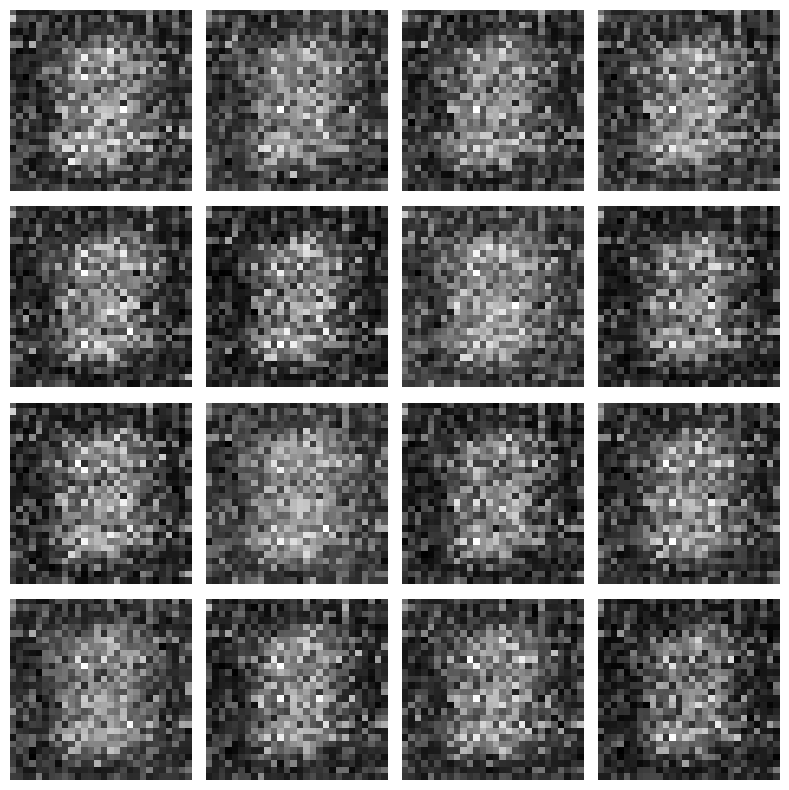

In [ ]:
noise = np.random.normal(0, 1, (16, latent_dim))

generated_images = generator.predict(noise, verbose=0)

generated_images = (generated_images + 1) / 2

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)

    plt.imshow(generated_images[i], cmap="gray")

    plt.axis("off")

plt.tight_layout()
plt.show()